In [1]:
print("hello")

hello


In [2]:
import os
print(os.getcwd())

C:\Users\loq\Desktop\fraud-detection\notebooks


In [3]:
import sys
sys.path.append("..")

import pandas as pd
from src.features import build_preprocessor

train = pd.read_csv("../data/processed/train.csv")
X_train = train.drop(columns="Class")
y_train = train["Class"]

print(X_train.shape, y_train.shape)

(227845, 30) (227845,)


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

baseline_pipeline = Pipeline([
    ("preprocessing", build_preprocessor()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
])

In [5]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    baseline_pipeline, X_train, y_train,
    cv=cv,
    scoring="average_precision",   # c'est la PR-AUC
)

print("PR-AUC par fold :", scores.round(4))
print(f"PR-AUC moyenne : {scores.mean():.4f} (+/- {scores.std():.4f})")

PR-AUC par fold : [0.8207 0.7557 0.681  0.8049 0.7256]
PR-AUC moyenne : 0.7576 (+/- 0.0512)


In [6]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

y_pred = cross_val_predict(baseline_pipeline, X_train, y_train, cv=cv)

print(confusion_matrix(y_train, y_pred))
print(classification_report(y_train, y_pred, target_names=["Normal", "Fraude"]))

[[221648   5803]
 [    36    358]]
              precision    recall  f1-score   support

      Normal       1.00      0.97      0.99    227451
      Fraude       0.06      0.91      0.11       394

    accuracy                           0.97    227845
   macro avg       0.53      0.94      0.55    227845
weighted avg       1.00      0.97      0.99    227845



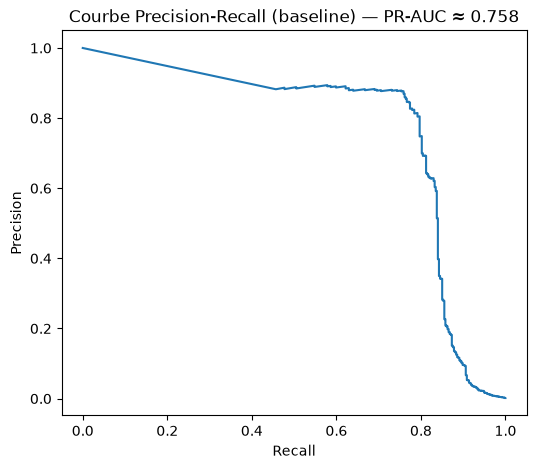

In [7]:
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay

y_proba = cross_val_predict(
    baseline_pipeline, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, y_proba)

plt.figure(figsize=(6, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Courbe Precision-Recall (baseline) — PR-AUC ≈ {scores.mean():.3f}")
plt.show()